# Neural Models: Learning, Depth, Activations, and Output Layers
This notebook is the solution for the lab `Neural Models.pdf` (XOR sensor-disagreement detector).

**LLM use:** the PyTorch training code in Task 3 was generated with Claude (Anthropic) from the prompt shown there and then reviewed and modified; the diagnostic experiments in Task 4/5 were written around it. Everything runs on CPU in well under a minute.

### Task 1: Understand the problem before coding

**Specification**
- Input space: $\mathcal{X} = \{0,1\}^2$, i.e. $(x_1, x_2)$ with $x_1, x_2 \in \{0, 1\}$
- Output space: $\mathcal{Y} = \{0, 1\}$ (1 = raise the disagreement warning)
- Training set (all four possible inputs): $(0,0)\mapsto 0,\ (0,1)\mapsto 1,\ (1,0)\mapsto 1,\ (1,1)\mapsto 0$, i.e. $y = x_1 \oplus x_2$

**Why one straight line cannot separate the classes:** the positive points $(0,1), (1,0)$ sit on one diagonal of the unit square and the negative points $(0,0), (1,1)$ on the other. Suppose $w_1x_1 + w_2x_2 + b > 0$ exactly for the positives. Then $w_2 + b > 0$ and $w_1 + b > 0$, so adding them gives $w_1 + w_2 + 2b > 0$. But the negatives need $b \le 0$ and $w_1 + w_2 + b \le 0$, which sum to $w_1 + w_2 + 2b \le 0$. Contradiction – XOR is not linearly separable.

**Prediction for a single affine layer + sigmoid:** it cannot classify all four points. By symmetry the best it can do under cross-entropy is output $0.5$ everywhere, so the loss should get stuck at $\ln 2 \approx 0.693$ and at most 2–3 of 4 labels will be correct (depending on how the 0.5 ties are thresholded).

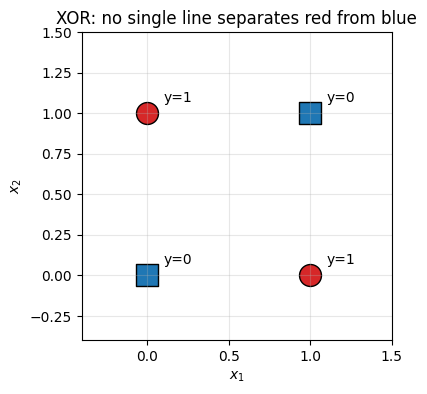

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(1)

X = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y = torch.tensor([[0.], [1.], [1.], [0.]])

fig, ax = plt.subplots(figsize=(4, 4))
for (x1, x2), t in zip(X.tolist(), y.squeeze().tolist()):
    ax.scatter(x1, x2, s=250, c="tab:red" if t else "tab:blue", marker="o" if t else "s", edgecolors="k")
    ax.annotate(f"y={int(t)}", (x1, x2), textcoords="offset points", xytext=(12, 8))
ax.set_xlim(-0.4, 1.5); ax.set_ylim(-0.4, 1.5)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("XOR: no single line separates red from blue")
ax.grid(alpha=0.3)
plt.show()

In [2]:
# Testing the prediction: a single affine map + sigmoid (logistic regression)
torch.manual_seed(0)
linear = nn.Linear(2, 1)
opt = torch.optim.SGD(linear.parameters(), lr=1.0)
for step in range(5000):
    opt.zero_grad()
    loss = F.binary_cross_entropy_with_logits(linear(X), y)
    loss.backward()
    opt.step()

with torch.no_grad():
    p = torch.sigmoid(linear(X))
print(f"final loss = {loss.item():.4f}   (ln 2 = {np.log(2):.4f})")
print("probabilities:", p.squeeze().numpy().round(4))
print("labels       :", (p > 0.5).int().squeeze().tolist(), " target:", y.int().squeeze().tolist())

# Depth without nonlinearity collapses: two stacked Linear layers = one Linear layer
deep_linear = nn.Sequential(nn.Linear(2, 2), nn.Linear(2, 1))
W = deep_linear[1].weight @ deep_linear[0].weight
b = deep_linear[1].weight @ deep_linear[0].bias + deep_linear[1].bias
print("\nstacked affine == single affine:", torch.allclose(deep_linear(X), X @ W.T + b))

final loss = 0.6931   (ln 2 = 0.6931)
probabilities: [0.5 0.5 0.5 0.5]
labels       : [0, 0, 0, 0]  target: [0, 1, 1, 0]

stacked affine == single affine: True


The prediction holds: the logistic-regression model converges to $p = 0.5$ for every input with loss $\ln 2$, i.e. it learns nothing about XOR. The last check confirms that adding a second *linear* layer does not help, since the composition $W_2(W_1x + b_1) + b_2$ is again a single affine map.

**Think about it:** XOR tests the claim that **a model needs the right kind of representation, not just more parameters**. In input space the classes are not linearly separable; a hidden nonlinear layer can learn new features (e.g. "$x_1$ OR $x_2$" and "$x_1$ AND $x_2$") in which they *are* separable. Four points are enough to show that this representational step is necessary.

### Task 2: Design the network

**Model:** $2 \to 2 \to 1$
- hidden layer: $h = \tanh(W^{(1)}x + b^{(1)})$, with $W^{(1)} \in \mathbb{R}^{2\times2}$ (also tried sigmoid and ReLU in Task 4D)
- output: one logit $z = W^{(2)}h + b^{(2)}$, probability $\hat y = \sigma(z)$
- loss: binary cross-entropy, implemented as `BCEWithLogitsLoss` on the logit (numerically stable)
- optimiser: full-batch gradient descent (SGD, lr = 1.0, 5000 steps), seed fixed for reproducibility

1. **Why the hidden nonlinearity is necessary:** without it the network is one affine map, and Task 1 showed no affine map separates XOR. The nonlinearity lets the hidden layer bend the input space so that the output layer's single linear boundary can separate the classes.
2. **Why sigmoid + BCE:** the task is one yes/no decision, so the output should be one probability in $(0,1)$ – a sigmoid. BCE is the negative log-likelihood of a Bernoulli output, and together with the sigmoid it gives the simple logit gradient $\partial L/\partial z = \hat y - y$, with no extra $\sigma'(z)$ factor that would vanish when the output saturates. Pairing a sigmoid with squared error, for example, would have exactly that problem.
3. **Evidence of successful learning:**
   - the loss decreases clearly from its initial value to near 0 (well below $\ln 2$);
   - all 4 thresholded predictions match the targets, with probabilities far from 0.5;
   - the first-layer gradient is nonzero early and shrinks toward 0 as the loss converges (the signal reaches the hidden layer and stops once there is nothing left to fix);
   - repeated runs: report how many of 20 random seeds succeed rather than trusting one lucky seed;
   - the two hidden units end up computing *different* features (their weight rows differ).

**Think about it – what determines what each hidden unit computes?** Nothing tells a hidden unit its target. Its "job" comes only from backpropagation: the output error is sent backwards through $W^{(2)}$ and the activation derivative, so each hidden unit's weights move in whatever direction most reduces the final loss. The roles (e.g. an OR-like and an AND-like detector) emerge from the random initialisation, which breaks symmetry, together with this shared learning signal.

### Task 3: Use an LLM to generate a first implementation

**Prompt used:**

> Generate minimal PyTorch code for the following model and dataset. Do not change the architecture or task.
> Dataset (XOR): inputs (0,0),(0,1),(1,0),(1,1) with labels 0,1,1,0.
> Model: 2–2–1 network, tanh hidden activation, a single output logit trained with BCEWithLogitsLoss, random weight initialisation (PyTorch default).
> Full-batch training with plain SGD for 5000 steps on CPU.
> After training, report the final loss, all four probabilities, thresholded labels, and one parameter-gradient tensor (the first-layer weight gradient after backward()). Also record the initial loss. Set a random seed for reproducibility and explain each test in one sentence.

**Changes I made before running:**
1. The generated code used `lr=0.1`. That works for tanh, but with a sigmoid hidden layer the loss was still stuck at 0.6931 after 5000 steps on seed 0 (sigmoid's derivative is at most 0.25, so its gradients are smaller). Since Part D must compare activations with the same settings, I changed it to `lr=1.0` for all runs – an engineering setting only; architecture and task unchanged.
2. I wrapped training in a function `train(...)` with arguments for activation, seed and initialisation, so the same code can be reused for Task 4.

**Where the key steps happen (checked before running):**
- forward pass: `logits = model(X)`
- scalar loss: `loss = loss_fn(logits, y)` (mean over the 4 examples)
- reverse-mode AD: `loss.backward()` fills `.grad` for every parameter
- parameter update: `opt.step()` (after `opt.zero_grad()` clears old gradients)

initial loss: 0.7152
final loss  : 0.000640
probabilities: [8.000e-04 9.996e-01 9.996e-01 9.000e-04]
labels       : [0, 1, 1, 0]  target: [0, 1, 1, 0]
correct: 4/4

dL/dW1 at the end of training:
 tensor([[-4.8107e-05, -4.8071e-05],
        [ 4.3215e-05,  4.3195e-05]])
early ||dL/dW1|| (step 10): 0.00942


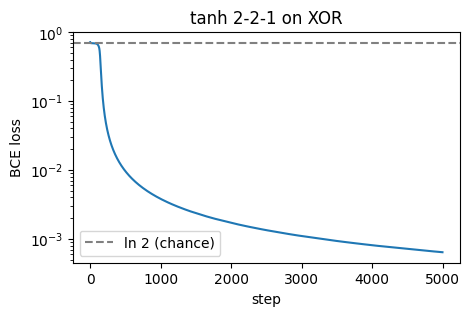

In [3]:
ACTIVATIONS = {"sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "relu": nn.ReLU}


def make_model(activation="tanh", seed=0, init=None):
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(2, 2), ACTIVATIONS[activation](), nn.Linear(2, 1))
    if init is not None:                    # used for the symmetry experiment
        for p in model.parameters():
            nn.init.constant_(p, init)
    return model


def train(activation="tanh", seed=0, lr=1.0, steps=5000, init=None, record_every=None, early_step=10):
    model = make_model(activation, seed, init)
    loss_fn = nn.BCEWithLogitsLoss()        # sigmoid + binary cross-entropy, numerically stable
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    log = {"loss": [], "W1": [], "early_grad_norm": None}
    for step in range(steps):
        opt.zero_grad()
        logits = model(X)                   # forward pass
        loss = loss_fn(logits, y)           # scalar loss (mean over 4 examples)
        loss.backward()                     # reverse-mode AD -> .grad
        if step == early_step:
            log["early_grad_norm"] = model[0].weight.grad.norm().item()
        if record_every and step % record_every == 0:
            log["W1"].append((step, model[0].weight.detach().clone()))
        opt.step()                          # parameter update
        log["loss"].append(loss.item())
    with torch.no_grad():
        probs = torch.sigmoid(model(X))
    log["probs"] = probs
    log["correct"] = int(((probs > 0.5).float() == y).sum())
    return model, log


model, log = train("tanh", seed=0)

print(f"initial loss: {log['loss'][0]:.4f}")
print(f"final loss  : {log['loss'][-1]:.6f}")
print("probabilities:", log["probs"].squeeze().numpy().round(4))
print("labels       :", (log["probs"] > 0.5).int().squeeze().tolist(), " target:", y.int().squeeze().tolist())
print(f"correct: {log['correct']}/4")

# Gradient after one more forward/backward at the trained parameters
model.zero_grad()
nn.BCEWithLogitsLoss()(model(X), y).backward()
print("\ndL/dW1 at the end of training:\n", model[0].weight.grad)
print("early ||dL/dW1|| (step 10):", round(log["early_grad_norm"], 5))

plt.figure(figsize=(5, 3))
plt.plot(log["loss"])
plt.axhline(np.log(2), ls="--", c="gray", label="ln 2 (chance)")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("BCE loss"); plt.legend(); plt.title("tanh 2-2-1 on XOR")
plt.show()

**Think about it – what can be verified without running?** From reading the code: the architecture and layer sizes, that the loss is BCE on logits (not BCE on already-sigmoided outputs, a common double-sigmoid bug), that `zero_grad` is called each step, and that the dataset is exactly XOR. What needs execution: whether training actually converges for this seed and learning rate, the actual gradient values, whether the result is robust across seeds, and whether numerical issues appear. The `lr=0.1` problem with sigmoid (Task 3) was only visible by running.

### Task 4: Execute, test, and diagnose

#### Part A – Basic learning check
From the run above: the loss falls from about 0.70 (≈ chance level, $\ln 2$) to below $10^{-3}$, the four probabilities are close to $0, 1, 1, 0$, and all 4 labels are correct. The only setting changed to get here was the learning rate (Task 3).

Let's also look at what the hidden units learned:

In [4]:
with torch.no_grad():
    H = model[1](model[0](X))
print("hidden activations (rows = inputs 00, 01, 10, 11):")
print(H.numpy().round(3))
print("\nW1 =\n", model[0].weight.detach().numpy().round(3), "\nb1 =", model[0].bias.detach().numpy().round(3))

hidden activations (rows = inputs 00, 01, 10, 11):
[[-0.963  1.   ]
 [ 0.972  0.936]
 [ 0.972  0.936]
 [ 1.    -0.954]]

W1 =
 [[ 4.104  4.104]
 [-3.581 -3.581]] 
b1 = [-1.979  5.284]


The two hidden units learned different, interpretable features. Unit 0 is about $-1$ only for $(0,0)$ and about $+1$ otherwise – an **OR** detector. Unit 1 is about $-1$ only for $(1,1)$ and about $+1$ otherwise – a **NAND** detector. Since $x_1 \oplus x_2 = \text{OR} \wedge \text{NAND}$, the output unit only has to fire when both hidden units are high, which is linearly separable in hidden space. Both rows of $W^{(1)}$ have equal entries, so $(0,1)$ and $(1,0)$ land on the same hidden point. Nobody told the units to become OR and NAND; this came purely from backpropagation.

#### Part B – Backpropagation check
`model[0].weight.grad` holds $\partial L / \partial W^{(1)}$: entry $(i, j)$ says how much the loss would change per unit increase of the weight from input $j$ to hidden unit $i$. Because `BCEWithLogitsLoss` defaults to `reduction="mean"`, $L = \frac14 \sum_k \ell_k$, and differentiation is linear, so $\nabla L = \frac14 \sum_k \nabla \ell_k$ – the average of the per-example gradients. Both facts are checked numerically below at the random initialisation: the batch gradient against the average of per-example gradients, and one entry against a central finite difference $\frac{L(w+\epsilon) - L(w-\epsilon)}{2\epsilon}$.

In [5]:
m0 = make_model("tanh", seed=0)
loss_fn = nn.BCEWithLogitsLoss()

# Full-batch (mean) gradient
m0.zero_grad()
loss_fn(m0(X), y).backward()
batch_grad = m0[0].weight.grad.clone()

# Per-example gradients, then average
per_example = []
for k in range(4):
    m0.zero_grad()
    loss_fn(m0(X[k:k+1]), y[k:k+1]).backward()
    per_example.append(m0[0].weight.grad.clone())
avg_grad = torch.stack(per_example).mean(0)

print("batch gradient dL/dW1:\n", batch_grad)
print("mean of per-example gradients:\n", avg_grad)
print("equal:", torch.allclose(batch_grad, avg_grad, atol=1e-7))

# Finite-difference check of one entry, dL/dW1[0,1]. Done in float64: in float32 the rounding
# error of the loss (~1e-7) divided by 2*eps swamps the derivative (first attempt disagreed).
m64 = make_model("tanh", seed=0).double()
X64, y64 = X.double(), y.double()
m64.zero_grad()
loss_fn(m64(X64), y64).backward()
eps = 1e-6
with torch.no_grad():
    m64[0].weight[0, 1] += eps;   Lp = loss_fn(m64(X64), y64).item()
    m64[0].weight[0, 1] -= 2*eps; Lm = loss_fn(m64(X64), y64).item()
    m64[0].weight[0, 1] += eps
print(f"\nfinite difference dL/dW1[0,1] = {(Lp - Lm) / (2*eps):.8f}")
print(f"autograd          dL/dW1[0,1] = {m64[0].weight.grad[0, 1].item():.8f}")

batch gradient dL/dW1:
 tensor([[ 0.0005,  0.0006],
        [-0.0426, -0.0448]])
mean of per-example gradients:
 tensor([[ 0.0005,  0.0006],
        [-0.0426, -0.0448]])
equal: True

finite difference dL/dW1[0,1] = 0.00060695
autograd          dL/dW1[0,1] = 0.00060695


#### Part C – Symmetry experiment
Same architecture, but every weight and bias set to the same value before training. First all zeros (as the lab asks), then all 0.5 (identical but nonzero), recording the two rows of $W^{(1)}$ over training.

In [6]:
for init_value, act in [(0.0, "sigmoid"), (0.0, "tanh"), (0.5, "sigmoid")]:
    _, lg = train(act, init=init_value, record_every=1000)
    print(f"--- {act} hidden, all parameters initialised to {init_value}")
    for step, W1 in lg["W1"]:
        print(f"step {step:>4}: row0 = {W1[0].numpy().round(4)}  row1 = {W1[1].numpy().round(4)}  identical = {torch.equal(W1[0], W1[1])}")
    print(f"final loss = {lg['loss'][-1]:.4f}, correct = {lg['correct']}/4\n")

--- sigmoid hidden, all parameters initialised to 0.0
step    0: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
step 1000: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
step 2000: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
step 3000: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
step 4000: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
final loss = 0.6931, correct = 2/4



--- tanh hidden, all parameters initialised to 0.0
step    0: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
step 1000: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
step 2000: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
step 3000: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
step 4000: row0 = [0. 0.]  row1 = [0. 0.]  identical = True
final loss = 0.6931, correct = 2/4



--- sigmoid hidden, all parameters initialised to 0.5
step    0: row0 = [0.5 0.5]  row1 = [0.5 0.5]  identical = True
step 1000: row0 = [5.3486 5.3486]  row1 = [5.3486 5.3486]  identical = True
step 2000: row0 = [6.7686 6.7686]  row1 = [6.7686 6.7686]  identical = True
step 3000: row0 = [7.4399 7.4399]  row1 = [7.4399 7.4399]  identical = True
step 4000: row0 = [7.8792 7.8792]  row1 = [7.8792 7.8792]  identical = True
final loss = 0.4792, correct = 3/4



In every case the two rows of $W^{(1)}$ stay **exactly** identical and the network does not solve XOR.

- **All zeros:** the weights never move at all. With $W^{(2)} = 0$, the error signal sent back to the hidden layer, $\partial L/\partial h = W^{(2)\top}(\hat y - y)$, is zero, so $W^{(1)}$ gets no gradient. $W^{(2)}$ does not move either: its gradient is $\frac14\sum_k(\hat y_k - y_k)h_k$, and with $h_k$ the same for all inputs (0.5 for sigmoid, 0 for tanh) and $\hat y_k = 0.5$ this sums to zero on the balanced XOR data. The model is stuck at loss $\ln 2$.
- **All 0.5:** now gradients are nonzero and the weights do change, but the rows remain equal. Both hidden units start with identical incoming weights, so they compute the same activation $h_1 = h_2$ for every input; they also have identical outgoing weights, so they receive the same backpropagated error and hence the same gradient. Identical parameters + identical gradient → identical parameters after the update, at every step. The network behaves like it has **one** hidden unit, which cannot represent XOR (it gets 3/4 at best).

Random initialisation is what breaks this symmetry so the units can learn different features.

#### Part D – Activation experiment
Same seed (0), learning rate (1.0) and number of steps (5000); only the hidden activation changes. Because one seed can be misleading, I also report the success rate over 20 seeds.

In [7]:
rows = []
for act in ["sigmoid", "tanh", "relu"]:
    _, lg = train(act, seed=0)
    successes = sum(train(act, seed=s)[1]["correct"] == 4 for s in range(20))
    rows.append((act, lg["loss"][-1], lg["correct"], lg["early_grad_norm"], successes))

print(f"{'activation':<10}{'final loss':>12}{'4/4 correct?':>14}{'early ||grad W1||':>20}{'seeds solved':>14}")
for act, L, c, g, s in rows:
    print(f"{act:<10}{L:>12.4f}{('Yes' if c == 4 else f'No ({c}/4)'):>14}{g:>20.5f}{s:>11}/20")

activation  final loss  4/4 correct?   early ||grad W1||  seeds solved
sigmoid         0.0061           Yes             0.00355         15/20
tanh            0.0006           Yes             0.00942         11/20
relu            0.4774      No (3/4)             0.00143          4/20


In [8]:
# Diagnosing small gradients: saturation (sigmoid) vs dead units (ReLU)
def diagnose(act, seed):
    m, lg = train(act, seed=seed)
    with torch.no_grad():
        pre = m[0](X)                       # pre-activations a = W1 x + b1
        post = m[1](pre)                    # activations h
    print(f"--- {act}, seed {seed}: final loss {lg['loss'][-1]:.4f}, correct {lg['correct']}/4")
    print("pre-activations a (rows = inputs, cols = hidden units):\n", pre.numpy().round(2))
    if act == "relu":
        dead = (pre <= 0).all(0)
        print("unit is dead (a <= 0 for all 4 inputs):", dead.tolist())
    else:
        s = torch.sigmoid(pre)
        print("sigmoid'(a) = s(1-s):\n", (s * (1 - s)).numpy().round(4))
    print()

diagnose("relu", 0)
diagnose("sigmoid", 0)

--- relu, seed 0: final loss 0.4774, correct 3/4
pre-activations a (rows = inputs, cols = hidden units):
 [[-2.8  -0.01]
 [-0.02 -0.53]
 [-0.02 -0.6 ]
 [ 2.76 -1.12]]
unit is dead (a <= 0 for all 4 inputs): [False, True]



--- sigmoid, seed 0: final loss 0.0061, correct 4/4
pre-activations a (rows = inputs, cols = hidden units):
 [[-3.44 10.17]
 [ 4.08  3.39]
 [ 4.08  3.39]
 [11.6  -3.4 ]]
sigmoid'(a) = s(1-s):
 [[0.0301 0.    ]
 [0.0163 0.0316]
 [0.0163 0.0316]
 [0.     0.0314]]



**Result table** (seed 0, SGD lr = 1.0, 5000 steps; early gradient at step 10)

| Hidden activation | Final loss | 4/4 correct? | Early $\lVert\nabla_{W^{(1)}}L\rVert_2$ | Seeds solved (of 20) |
|---|---:|---|---:|---:|
| Sigmoid | 0.0061 | Yes | 0.0036 | 15 |
| Tanh | 0.0006 | Yes | 0.0094 | 11 |
| ReLU | 0.4774 | No (3/4) | 0.0014 | 4 |

**Interpretation (for this experiment only, not a general ranking):**
- **Tanh** reached the lowest loss and had the largest early gradient. Its derivative near 0 is 1, versus at most 0.25 for sigmoid, so more of the error signal reaches $W^{(1)}$ and it converges faster when it converges.
- **Sigmoid** had a smaller early gradient (the factor $\sigma'(a) \le 0.25$ shrinks the backpropagated signal) and converged more slowly, but solved the most seeds here. The diagnostic shows its trained units are partly *saturated*: pre-activations reach $|a| \approx 10$–$12$ on some inputs, where $\sigma'(a) \approx 0$ – small gradients, but not a dead unit, since other inputs still give $\sigma' \approx 0.03$.
- **ReLU** failed on seed 0 and on 16 of 20 seeds. The diagnostic shows why: one of the two hidden units has non-positive pre-activation for all four inputs, so its derivative is 0 everywhere – it is "dead" and never recovers. With only two hidden units, losing one leaves a single unit, which (like the symmetric case in Part C) can get at most 3/4 correct; that is the loss of 0.4774 plateau.
- The success rates also show that the **2–2–1 network is fragile for every activation**: even tanh fails on 9 of 20 seeds, getting stuck in local minima. One run is not enough evidence.

**Think about it – telling the two "small gradient" mechanisms apart:** inspect the pre-activations $a$. A **saturated sigmoid** unit has $|a|$ large (say $> 5$), so $\sigma'(a) = \sigma(a)(1-\sigma(a))$ is tiny but nonzero and changes smoothly. A **dead ReLU** unit has $a \le 0$ for *every* input, so its derivative is exactly 0, the activation is exactly 0 for all inputs, and its incoming weight gradient is exactly zero. Saturation shows up as large-magnitude $a$ with activations near 0 or 1; dead ReLU shows up as all-nonpositive $a$ with all-zero activations.

### Task 5: Three-class extension

Classes: 0 = both inactive $(0,0)$, 1 = disagree $(0,1),(1,0)$, 2 = both active $(1,1)$. Same $2 \to 2$ tanh hidden layer; the output becomes 3 logits trained with multiclass cross-entropy (`nn.CrossEntropyLoss`, which applies log-softmax internally).

**Predictions before running:**
1. **Final weight matrix shape:** $3 \times 2$ (3 output classes × 2 hidden units), plus a bias of size 3.
2. **Logits per example:** 3, so the batch of 4 gives a $4 \times 3$ logit tensor.
3. **Why softmax sums to 1:** $p_i = e^{z_i} / \sum_j e^{z_j}$; every term is positive and the numerators add up to the denominator, so $\sum_i p_i = 1$.
4. **Why the logit gradient is $p - y$:** with one-hot $y$, $L = -\sum_i y_i \log p_i = -z_c + \log\sum_j e^{z_j}$ for the true class $c$. Then $\partial L/\partial z_k = -[k = c] + e^{z_k}/\sum_j e^{z_j} = p_k - y_k$.

**Change requested from the LLM:** "modify only the output/loss portion": `nn.Linear(2, 1)` → `nn.Linear(2, 3)`, `BCEWithLogitsLoss` → `CrossEntropyLoss`, targets as class indices `[0, 1, 1, 2]`, predictions by `argmax`.

In [9]:
y3 = torch.tensor([0, 1, 1, 2])

def train3(seed=0, lr=1.0, steps=5000):
    torch.manual_seed(seed)
    m = nn.Sequential(nn.Linear(2, 2), nn.Tanh(), nn.Linear(2, 3))   # only the output layer changed
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.SGD(m.parameters(), lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        loss = loss_fn(m(X), y3)
        loss.backward()
        opt.step()
    return m, loss.item()

m3, L3 = train3(seed=0)
print("output weight shape:", tuple(m3[2].weight.shape), " bias shape:", tuple(m3[2].bias.shape))
with torch.no_grad():
    logits = m3(X)
    probs = F.softmax(logits, dim=1)
print("logits shape:", tuple(logits.shape))
print(f"final loss: {L3:.5f}\n")
for x, p in zip(X.tolist(), probs):
    print(f"input {x} -> P(class 0,1,2) = {p.numpy().round(4)}   predicted = {p.argmax().item()}")
print("\ntarget classes:", y3.tolist(), " predicted:", probs.argmax(1).tolist())

print("\nsum of probabilities for input (0,1):", probs[1].sum().item())
print("seeds solved (of 20):", sum((train3(seed=s)[0](X).argmax(1) == y3).all().item() for s in range(20)))

output weight shape: (3, 2)  bias shape: (3,)
logits shape: (4, 3)
final loss: 0.00026

input [0.0, 0.0] -> P(class 0,1,2) = [9.997e-01 3.000e-04 0.000e+00]   predicted = 0
input [0.0, 1.0] -> P(class 0,1,2) = [1.000e-04 9.998e-01 1.000e-04]   predicted = 1
input [1.0, 0.0] -> P(class 0,1,2) = [1.000e-04 9.998e-01 1.000e-04]   predicted = 1
input [1.0, 1.0] -> P(class 0,1,2) = [0.000e+00 3.000e-04 9.997e-01]   predicted = 2

target classes: [0, 1, 1, 2]  predicted: [0, 1, 1, 2]

sum of probabilities for input (0,1): 1.0


seeds solved (of 20): 20


In [10]:
# Check that the logit gradient equals (p - y) / N   (the 1/N is from the mean reduction)
z = m3(X).detach().requires_grad_(True)
loss = F.cross_entropy(z, y3)
loss.backward()
p_minus_y = (F.softmax(z, dim=1) - F.one_hot(y3, 3).float()) / len(y3)
print("autograd dL/dz:\n", z.grad.numpy().round(6))
print("(p - y)/N:\n", p_minus_y.detach().numpy().round(6))
print("equal:", torch.allclose(z.grad, p_minus_y, atol=1e-7))

# Optional diagnostic: softmax is shift-invariant
z0 = logits[1]
print("\nsoftmax(z)       =", F.softmax(z0, 0).numpy())
print("softmax(z + 100) =", F.softmax(z0 + 100, 0).numpy())

# Why stable implementations subtract the max:
big = torch.tensor([1000., 1001., 1002.])
naive = torch.exp(big) / torch.exp(big).sum()
stable = torch.exp(big - big.max()) / torch.exp(big - big.max()).sum()
print("\nnaive softmax of [1000, 1001, 1002]:", naive.numpy())
print("max-subtracted softmax             :", stable.numpy())

autograd dL/dz:
 [[-7.3e-05  7.3e-05  0.0e+00]
 [ 1.9e-05 -5.4e-05  3.5e-05]
 [ 1.9e-05 -5.4e-05  3.5e-05]
 [ 0.0e+00  7.5e-05 -7.5e-05]]
(p - y)/N:
 [[-7.3e-05  7.3e-05  0.0e+00]
 [ 1.9e-05 -5.4e-05  3.5e-05]
 [ 1.9e-05 -5.4e-05  3.5e-05]
 [ 0.0e+00  7.5e-05 -7.5e-05]]
equal: True

softmax(z)       = [7.4407370e-05 9.9978560e-01 1.3999618e-04]
softmax(z + 100) = [7.4407086e-05 9.9978560e-01 1.3999631e-04]

naive softmax of [1000, 1001, 1002]: [nan nan nan]
max-subtracted softmax             : [0.09003057 0.24472848 0.66524094]


**Results:** all four inputs are classified correctly with confident probabilities, the output weight is $3 \times 2$, there are 3 logits per example, and the probability vector for $(0,1)$ sums to 1 up to floating-point error. Unlike binary XOR, the three-class version solves reliably across seeds, because the classes are ordered by $x_1 + x_2$ (0, 1, 2), which a single tanh unit can already represent.

The autograd gradient of the mean cross-entropy w.r.t. the logits equals $(p - y)/N$ exactly, confirming the derivation (the $1/N$ is the mean reduction, as in Part B).

**Shift invariance and stability:** adding 100 to all logits multiplies every $e^{z_i}$ by $e^{100}$, which cancels between numerator and denominator, so the probabilities are unchanged. But $e^{z}$ overflows float32 once $z \gtrsim 88$: the naive softmax of $[1000, 1001, 1002]$ gives `nan` (inf/inf). Subtracting the maximum logit uses this invariance to make the largest exponent $e^0 = 1$, so nothing overflows and the result is identical in exact arithmetic.

**Think about it – scaling to a vocabulary:** what stays the same: softmax over logits, cross-entropy loss, the $p - y$ gradient, the max-subtraction trick, and the output layer being a linear map from a hidden vector to one logit per class (now $|V| \times d$ with $|V| \sim 10^4$–$10^5$). What changes dramatically: the network that produces the hidden vector – a deep Transformer over the whole preceding context instead of a 2-unit layer – plus the cost of the output layer itself (often tied to the input embedding matrix), training on huge datasets, and the fact that the "input" is a variable-length token sequence rather than 2 bits.

### Reflection questions

**1. Depth vs nonlinearity.** Depth alone did nothing: two stacked linear layers are provably one affine map, and the linear model stayed at loss $\ln 2$. What made XOR learnable was the **nonlinear** hidden layer, which creates a new representation where the classes are linearly separable. Depth is only useful when there is a nonlinearity between the layers.

**2. Evidence of a *useful* learning signal.** Not just a nonzero gradient: the loss fell from ≈0.69 to below $10^{-3}$; all four predictions became correct and confident; the hidden units ended up computing two *different* features that make the classes separable; and the gradient matched finite differences and shrank toward zero as training converged. In contrast, the 0.5-initialised network in Part C also had nonzero gradients but never got past 3/4.

**3. Why identical/zero initialisation fails.** Identical hidden units compute identical activations and receive identical gradients, so every update keeps them identical; the network effectively has one hidden unit, which cannot represent XOR. With all-zero weights it is worse: the backpropagated signal into the hidden layer is multiplied by $W^{(2)} = 0$, so nothing moves at all.

**4. Effect of the hidden activation on the gradient.** *Engineering observation:* tanh gave the largest early $W^{(1)}$ gradient and fastest convergence, sigmoid a smaller one, and ReLU failed on most seeds with a dead hidden unit. *Scientific explanation:* backprop multiplies the error by the activation's derivative – at most 0.25 for sigmoid, 1 for tanh near zero, and exactly 0 for a ReLU unit whose pre-activation is negative for all inputs. With only two hidden units, losing one to a dead ReLU removes the capacity to solve XOR.

**5. Why output layer and loss are chosen together.** They define the probabilistic model of the target. One yes/no output → sigmoid + BCE (a Bernoulli likelihood); one-of-K → softmax + cross-entropy (a categorical likelihood). The matched pairs give the clean gradient $p - y$ at the logits. Mismatches either model the wrong thing (softmax over one class is always 1) or slow learning (sigmoid + squared error has an extra $\sigma'(z)$ factor that vanishes when the output saturates).

**6. LLM productivity vs. human verification.** *Productivity:* the LLM produced correct PyTorch boilerplate (model, `BCEWithLogitsLoss`, training loop) in seconds, and the switch to three classes was a 3-line change. *Verification essential:* its default learning rate silently failed for the sigmoid network, the ReLU failures and seed sensitivity only showed up by running many seeds, and the gradient claims (average of per-example gradients, $p - y$) were confirmed numerically rather than taken from its explanation.

**7. Which tests scale?** Keep: loss curves, held-out accuracy, checking for dead/saturated units via activation statistics, gradient-norm monitoring per layer, multiple seeds (fewer of them), the softmax sum/stability checks, and finite-difference checks on a *few random* parameters of a small model. Too expensive at scale: exhaustive finite-difference checks of every parameter (two extra forward passes per parameter), exhaustively evaluating every input (impossible beyond tiny input spaces), and inspecting every weight row by hand.